# Logistic Regression from Scratch (NumPy)
### Breast cancer classification with L2 regularization, threshold analysis and cross-validation

This notebook implements **logistic regression with L2 regularization using only NumPy**, trains it with batch gradient descent, and validates it against scikit-learn.

**What you will find here**

1. Data loading and exploration
2. Stratified train / validation / test split
3. Feature standardization (fitted on the training set only, to avoid leakage)
4. The model: sigmoid, regularized cross-entropy cost and its gradient
5. Training with a convergence tolerance
6. Evaluation: confusion matrix, precision, recall, F1
7. Decision-threshold selection on the validation set
8. Final, untouched test-set evaluation
9. Stratified 5-fold cross-validation
10. Verification against scikit-learn
11. Feature weights (interpretation)

> **Disclaimer:** this is an educational project on a public teaching dataset. It is **not** a medical tool and must not be used for clinical decisions.

## 1. Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression  # used ONLY to verify the from-scratch model

SEED = 42
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 2. Model implementation

For a sample with features $x$, weights $w$ and bias $b$:

$$z = w^\top x + b, \qquad f(x) = \sigma(z) = \frac{1}{1 + e^{-z}}$$

The regularized binary cross-entropy cost over $m$ samples is

$$J(w, b) = -\frac{1}{m}\sum_{i=1}^{m}\Big[y_i \log f_i + (1-y_i)\log(1-f_i)\Big] + \frac{\lambda}{2m}\lVert w \rVert_2^2$$

and its gradients are

$$\frac{\partial J}{\partial w} = \frac{1}{m} X^\top (f - y) + \frac{\lambda}{m} w, \qquad \frac{\partial J}{\partial b} = \frac{1}{m}\sum_i (f_i - y_i)$$

The bias $b$ is **not** regularized.

**Numerical stability.** Two guards prevent `inf` / `nan`: the argument of `exp` is clipped, and the probabilities are clipped away from exactly 0 and 1 before taking the logarithm. The gradient does not need the logarithm, so training itself is unaffected.

In [2]:
def sigmoid(z):
    """Numerically stable sigmoid."""
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))


def predict_proba(x, w, b):
    """Probability of the positive class for every row of x."""
    return sigmoid(x @ w + b)


def cost(x, y, w, b, lambda_=0.0):
    """Regularized binary cross-entropy (the bias is not penalized)."""
    m = len(x)
    f = np.clip(predict_proba(x, w, b), 1e-15, 1 - 1e-15)
    loss = -np.mean(y * np.log(f) + (1 - y) * np.log(1 - f))
    return loss + (lambda_ / (2 * m)) * np.sum(w ** 2)


def gradient(x, y, w, b, lambda_=0.0):
    """Gradients of the regularized cost with respect to w and b."""
    m = len(x)
    error = predict_proba(x, w, b) - y
    dw = (x.T @ error) / m + (lambda_ / m) * w
    db = np.mean(error)
    return dw, db


def fit(x, y, alpha=0.5, max_iter=20000, lambda_=1.0, tol=1e-12, verbose=True):
    """Batch gradient descent with early stopping on cost improvement."""
    w = np.zeros(x.shape[1])
    b = 0.0
    history = []
    for i in range(max_iter):
        dw, db = gradient(x, y, w, b, lambda_)
        w = w - alpha * dw
        b = b - alpha * db
        history.append(cost(x, y, w, b, lambda_))
        if verbose and i % 500 == 0:
            print(f"iter {i:5d} | cost = {history[-1]:.6f}")
        if i > 0 and abs(history[-2] - history[-1]) < tol:
            if verbose:
                print(f"converged at iter {i} | cost = {history[-1]:.6f}")
            break
    return w, b, history

## 3. Evaluation helpers

All metrics are computed from the confusion matrix. The **positive class is "malignant"**, so recall answers the question that matters most here: *of all truly malignant cases, how many did we catch?*

In [3]:
def confusion(y_true, y_pred):
    tp = int(np.sum((y_pred == 1) & (y_true == 1)))
    fp = int(np.sum((y_pred == 1) & (y_true == 0)))
    fn = int(np.sum((y_pred == 0) & (y_true == 1)))
    tn = int(np.sum((y_pred == 0) & (y_true == 0)))
    return tp, fp, fn, tn


def metrics(y_true, y_pred):
    tp, fp, fn, tn = confusion(y_true, y_pred)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {
        "tp": tp, "fp": fp, "fn": fn, "tn": tn,
        "accuracy": (tp + tn) / len(y_true),
        "precision": precision, "recall": recall, "f1": f1,
    }


def fbeta(precision, recall, beta=2.0):
    """F-beta score. beta > 1 weights recall more than precision."""
    denom = beta ** 2 * precision + recall
    return (1 + beta ** 2) * precision * recall / denom if denom else 0.0


def stratified_split(y, fractions, seed=SEED):
    """Split indices so every part keeps the class ratio of y."""
    rng = np.random.default_rng(seed)
    parts = [[] for _ in fractions]
    for cls in np.unique(y):
        idx = rng.permutation(np.where(y == cls)[0])
        cuts = (np.cumsum(fractions)[:-1] * len(idx)).astype(int)
        for part, chunk in zip(parts, np.split(idx, cuts)):
            part.extend(chunk.tolist())
    return [rng.permutation(np.array(p)) for p in parts]


def stratified_kfold(y, k=5, seed=SEED):
    """Yield (train_idx, test_idx) pairs with stratified folds."""
    rng = np.random.default_rng(seed)
    folds = [[] for _ in range(k)]
    for cls in np.unique(y):
        idx = rng.permutation(np.where(y == cls)[0])
        for f, chunk in enumerate(np.array_split(idx, k)):
            folds[f].extend(chunk.tolist())
    folds = [np.array(f) for f in folds]
    for i in range(k):
        train = np.concatenate([folds[j] for j in range(k) if j != i])
        yield train, folds[i]

## 4. Data

The **Breast Cancer Wisconsin (Diagnostic)** dataset ships with scikit-learn (originally from the UCI repository): 569 samples, 30 numeric features computed from digitized images of fine-needle aspirates.

scikit-learn encodes `0 = malignant` and `1 = benign`. We flip it so that **1 = malignant (positive class)**.

In [4]:
data = load_breast_cancer()
X = data.data
y = 1 - data.target.astype(float)          # 1 = malignant, 0 = benign
feature_names = data.feature_names

print(f"samples : {X.shape[0]}")
print(f"features: {X.shape[1]}")
print(f"malignant ratio : {y.mean():.3f}")
print(f"missing values  : {int(np.isnan(X).sum())}")
print(f"baseline accuracy (always predict benign): {(y == 0).mean():.3f}")

samples : 569
features: 30
malignant ratio : 0.373
missing values  : 0
baseline accuracy (always predict benign): 0.627


The baseline above is the accuracy of a model that always answers "benign". Any useful model has to beat it clearly.

## 5. Stratified train / validation / test split (60 / 20 / 20)

* **Train** fits the weights.
* **Validation** is used to choose the decision threshold.
* **Test** is touched **once**, at the very end.

Stratification keeps the malignant ratio identical in all three parts, which matters with a small test set.

In [5]:
train_idx, val_idx, test_idx = stratified_split(y, fractions=[0.6, 0.2, 0.2])

X_train, y_train = X[train_idx], y[train_idx]
X_val,   y_val   = X[val_idx],   y[val_idx]
X_test,  y_test  = X[test_idx],  y[test_idx]

for name, part in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:<5}: {len(part):3d} rows | malignant ratio = {part.mean():.3f}")

train: 341 rows | malignant ratio = 0.372
val  : 113 rows | malignant ratio = 0.372
test : 115 rows | malignant ratio = 0.374


## 6. Feature standardization

Features live on very different scales (areas in the hundreds, smoothness values below 1). Without scaling, gradient descent diverges or crawls.

The mean and standard deviation are computed **on the training set only** and reused for validation and test. Computing them on all data would leak information from the evaluation sets.

In [6]:
mu = X_train.mean(axis=0)
sigma = X_train.std(axis=0)
sigma[sigma == 0] = 1.0                     # guard against constant features

X_train_s = (X_train - mu) / sigma
X_val_s   = (X_val   - mu) / sigma
X_test_s  = (X_test  - mu) / sigma

## 7. Training

`alpha` is the learning rate and `lambda_` the L2 strength. Training stops early once the cost improvement falls below the tolerance.

In [7]:
w, b, history = fit(X_train_s, y_train, alpha=0.5, max_iter=20000, lambda_=1.0)

print("\ncost contains NaN:", bool(np.isnan(history).any()))

iter     0 | cost = 0.217408
iter   500 | cost = 0.065554


iter  1000 | cost = 0.065183

iter  1500 | cost = 0.065138
iter  2000 | cost = 0.065131


iter  2500 | cost = 0.065130


iter  3000 | cost = 0.065130
iter  3500 | cost = 0.065130


iter  4000 | cost = 0.065130
iter  4500 | cost = 0.065130


converged at iter 4585 | cost = 0.065130

cost contains NaN: False


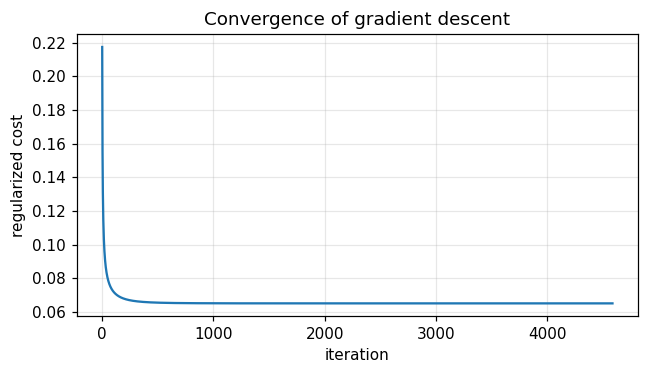

In [8]:
plt.figure(figsize=(6, 3.5))
plt.plot(history, color="#1f77b4")
plt.xlabel("iteration")
plt.ylabel("regularized cost")
plt.title("Convergence of gradient descent")
plt.tight_layout()
plt.show()

## 8. Evaluation with the default threshold (0.5)

In [9]:
p_val = predict_proba(X_val_s, w, b)
m = metrics(y_val, (p_val >= 0.5).astype(float))

print("Validation set @ threshold 0.5")
for key in ["accuracy", "precision", "recall", "f1"]:
    print(f"  {key:<9}: {m[key]:.3f}")
print(f"  TP={m['tp']}  FP={m['fp']}  FN={m['fn']}  TN={m['tn']}")

Validation set @ threshold 0.5
  accuracy : 0.973
  precision: 1.000
  recall   : 0.929
  f1       : 0.963
  TP=39  FP=0  FN=3  TN=71


## 9. Choosing the decision threshold (on validation data)

A threshold of 0.5 is not sacred. In a screening setting, **missing a malignant case (false negative) is worse than an extra follow-up test (false positive)**, so we select the threshold that maximizes the **F2 score**, which weights recall twice as much as precision.

The choice is made on the **validation** set. Choosing it on the test set would be a subtle form of leakage.

In [10]:
thresholds = np.round(np.arange(0.05, 0.96, 0.05), 2)
rows = []
for t in thresholds:
    r = metrics(y_val, (p_val >= t).astype(float))
    rows.append((t, r["precision"], r["recall"], r["f1"], fbeta(r["precision"], r["recall"])))
rows = np.array(rows)

best = rows[np.argmax(rows[:, 4])]
best_threshold = float(best[0])

print(f"{'thr':>5} {'precision':>10} {'recall':>8} {'F1':>7} {'F2':>7}")
for t, pr, rc, f1, f2 in rows[::2]:
    print(f"{t:5.2f} {pr:10.3f} {rc:8.3f} {f1:7.3f} {f2:7.3f}")
print(f"\nSelected threshold (max F2 on validation): {best_threshold:.2f}")

  thr  precision   recall      F1      F2
 0.05      0.774    0.976   0.863   0.928
 0.15      0.851    0.952   0.899   0.930
 0.25      0.930    0.952   0.941   0.948
 0.35      0.975    0.929   0.951   0.938
 0.45      1.000    0.929   0.963   0.942
 0.55      1.000    0.929   0.963   0.942
 0.65      1.000    0.905   0.950   0.922
 0.75      1.000    0.905   0.950   0.922
 0.85      1.000    0.905   0.950   0.922
 0.95      1.000    0.810   0.895   0.842

Selected threshold (max F2 on validation): 0.30


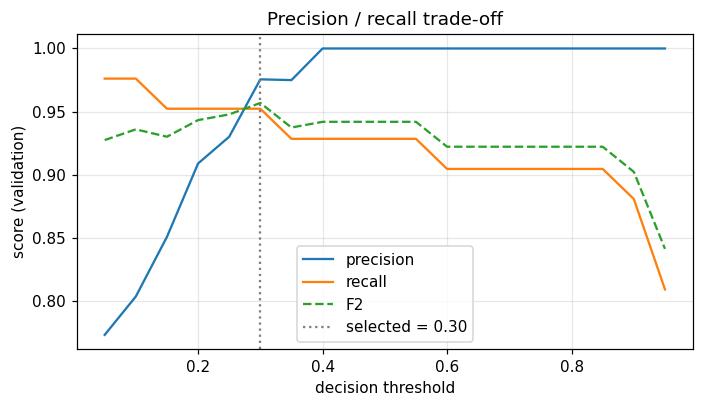

In [11]:
plt.figure(figsize=(6.5, 3.8))
plt.plot(rows[:, 0], rows[:, 1], label="precision")
plt.plot(rows[:, 0], rows[:, 2], label="recall")
plt.plot(rows[:, 0], rows[:, 4], label="F2", linestyle="--")
plt.axvline(best_threshold, color="grey", linestyle=":", label=f"selected = {best_threshold:.2f}")
plt.xlabel("decision threshold")
plt.ylabel("score (validation)")
plt.title("Precision / recall trade-off")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Final evaluation on the test set

The test set is used exactly once, with the threshold fixed beforehand.

In [12]:
p_test = predict_proba(X_test_s, w, b)

for label, t in [("default 0.50", 0.5), (f"selected {best_threshold:.2f}", best_threshold)]:
    m = metrics(y_test, (p_test >= t).astype(float))
    print(f"Test @ threshold {label}")
    print(f"  accuracy={m['accuracy']:.3f}  precision={m['precision']:.3f}  "
          f"recall={m['recall']:.3f}  f1={m['f1']:.3f}")
    print(f"  TP={m['tp']}  FP={m['fp']}  FN={m['fn']}  TN={m['tn']}\n")

print(f"Baseline accuracy (always benign): {(y_test == 0).mean():.3f}")

Test @ threshold default 0.50
  accuracy=0.983  precision=1.000  recall=0.953  f1=0.976
  TP=41  FP=0  FN=2  TN=72

Test @ threshold selected 0.30
  accuracy=1.000  precision=1.000  recall=1.000  f1=1.000
  TP=43  FP=0  FN=0  TN=72

Baseline accuracy (always benign): 0.626


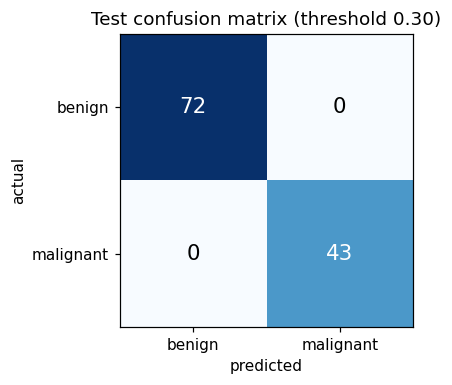

In [13]:
m = metrics(y_test, (p_test >= best_threshold).astype(float))
cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])

fig, ax = plt.subplots(figsize=(4, 3.6))
ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_xticklabels(["benign", "malignant"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["benign", "malignant"])
ax.set_xlabel("predicted"); ax.set_ylabel("actual")
ax.set_title(f"Test confusion matrix (threshold {best_threshold:.2f})")
ax.grid(False)
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, str(v), ha="center", va="center",
            color="white" if v > cm.max() / 2 else "black", fontsize=14)
plt.tight_layout()
plt.show()

> **Read this carefully.** With only ~115 test rows (43 malignant), one patient moves recall by about 2.3 points, and a perfect score at one threshold is partly luck of the split. Do not present a single test number as the model's true performance. The cross-validated estimate in the next section is the more honest one.

## 11. Stratified 5-fold cross-validation

A single split of ~110 test rows is noisy: one patient moves recall by almost 3 points. Cross-validation over the whole development set (train + validation) gives a mean and a spread instead of one lucky or unlucky number.

In [14]:
dev_idx = np.concatenate([train_idx, val_idx])
X_dev, y_dev = X[dev_idx], y[dev_idx]

scores = {"accuracy": [], "precision": [], "recall": [], "f1": []}
for tr, te in stratified_kfold(y_dev, k=5):
    mu_f, sd_f = X_dev[tr].mean(axis=0), X_dev[tr].std(axis=0)
    sd_f[sd_f == 0] = 1.0
    w_f, b_f, _ = fit((X_dev[tr] - mu_f) / sd_f, y_dev[tr],
                      alpha=0.5, max_iter=20000, lambda_=1.0, verbose=False)
    pred = (predict_proba((X_dev[te] - mu_f) / sd_f, w_f, b_f) >= 0.5).astype(float)
    r = metrics(y_dev[te], pred)
    for key in scores:
        scores[key].append(r[key])

print("5-fold CV @ threshold 0.5  (mean +/- std)")
for key, vals in scores.items():
    print(f"  {key:<9}: {np.mean(vals):.3f} +/- {np.std(vals):.3f}")

5-fold CV @ threshold 0.5  (mean +/- std)
  accuracy : 0.967 +/- 0.007
  precision: 0.971 +/- 0.030
  recall   : 0.941 +/- 0.033
  f1       : 0.955 +/- 0.010


## 12. Verification against scikit-learn

With this cost function, `lambda_` corresponds to `C = 1 / lambda_` in scikit-learn (the intercept is unpenalized in both). If the implementation is correct, predictions should be identical and the weights should agree to within about 1e-2 (the two optimizers, plain gradient descent vs. L-BFGS, stop at slightly different points of a very flat minimum).

In [15]:
clf = LogisticRegression(C=1.0, max_iter=10000)
clf.fit(X_train_s, y_train)

print(f"sklearn test accuracy : {clf.score(X_test_s, y_test):.4f}")
print(f"scratch test accuracy : {np.mean((p_test >= 0.5) == y_test):.4f}")
print(f"max |w_scratch - w_sklearn| : {np.max(np.abs(w - clf.coef_[0])):.2e}")
print(f"|b_scratch - b_sklearn|     : {abs(b - clf.intercept_[0]):.2e}")
print("weights match (atol=1e-2):", bool(np.allclose(w, clf.coef_[0], atol=1e-2)))

sklearn test accuracy : 0.9826
scratch test accuracy : 0.9826
max |w_scratch - w_sklearn| : 7.86e-03
|b_scratch - b_sklearn|     : 6.35e-04
weights match (atol=1e-2): True


## 13. Feature weights

Because the features are standardized, weights are comparable in magnitude: a larger absolute weight means a stronger influence on the predicted log-odds of malignancy.

**Caveat:** many features are highly correlated (radius, perimeter and area measure almost the same thing). In that case the model splits the weight between them somewhat arbitrarily, so a small weight does not prove that a feature is unimportant.

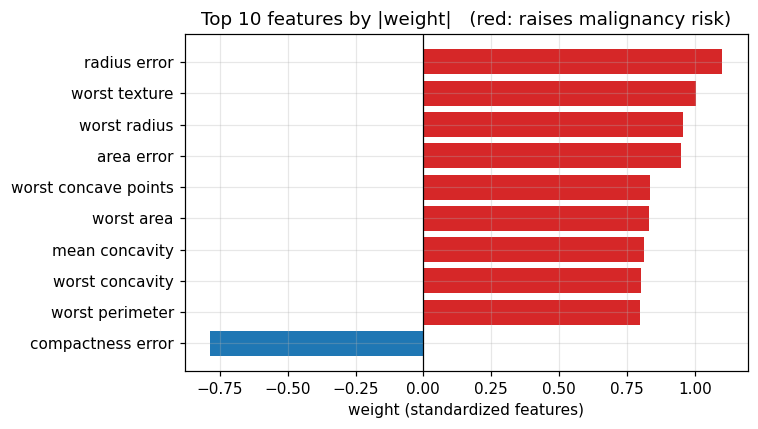

bias b = -0.366


In [16]:
order = np.argsort(-np.abs(w))[:10]

plt.figure(figsize=(7, 4))
colors = ["#d62728" if w[i] > 0 else "#1f77b4" for i in order][::-1]
plt.barh([feature_names[i] for i in order][::-1], w[order][::-1], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("weight (standardized features)")
plt.title("Top 10 features by |weight|   (red: raises malignancy risk)")
plt.tight_layout()
plt.show()

print(f"bias b = {b:.3f}")

## 14. Summary, limitations and next steps

**Summary**

* A regularized logistic regression written in pure NumPy reaches the same test accuracy as scikit-learn, with weights that agree to about 1e-2.
* It clearly beats the majority-class baseline.
* The decision threshold was chosen on validation data to favor recall, and the test set was used only once.

**Limitations**

* The dataset is small (569 rows), so every metric has noticeable variance. Prefer the cross-validated numbers over any single split.
* Features are strongly correlated, so individual weights should be interpreted cautiously.
* Educational dataset only; no clinical validation of any kind.

**Possible next steps**

* Tune `lambda_` and `alpha` with nested cross-validation.
* Add an ROC curve and AUC computed from scratch.
* Try the same code on a harder, imbalanced dataset (e.g. Framingham heart study) to see how the picture changes.
* Compare with other models (regularized SVM, gradient boosting).

**Data source:** Wolberg, W. H., Street, W. N., Mangasarian, O. L., *Breast Cancer Wisconsin (Diagnostic)*, UCI Machine Learning Repository.